# MLP (R4)

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

This is our neural network for both tasks: predicting the maths score (regression) and flagging students below Level 2 (classification). We use scikit-learn's `MLPClassifier` and `MLPRegressor` on the 17 predictors and their `_missing` flags, tune the network size and the penalty on PV1, check the winners trained long enough, then run all 10 plausible values on the 5 school folds and combine them with Rubin's rules. At the end we compare it with our gradient boosting baseline.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_mlp_params.json` |
| `../data/clean/columns.json` | `outputs/ahmed_mlp_results.csv` |
| `../data/clean/folds.csv` | `outputs/figures/ahmed_mlp_learning_curve.png` |
| `../03_baselines/outputs/ahmed_hgb_results.csv` | `outputs/figures/ahmed_mlp_vs_hgb.png` |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             root_mean_squared_error, mean_absolute_error, r2_score)

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
INPUTS = FEATURES + [f"{c}_missing" for c in FEATURES]
PVS = range(1, 11)
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# no reading or science scores, no plausible values among the inputs
assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in INPUTS)
X = df[INPUTS]
print(X.shape, "| blanks to fill:", int(X.isna().sum().sum()))

(61775, 34) | blanks to fill: 124267


Unlike the trees, the MLP can't take blanks, and it needs inputs on similar scales. So each model is a pipeline: fill blanks with the median, standardise, then the network. The pipeline learns the medians and the scaling from the training folds only. The `_missing` flags go in as extra inputs, since in the EDA a blank answer went with 17 to 45 points lower in maths and the median alone would hide that.

# 1.1) The loop
The same loop as the gradient boosting notebook, with the model swapped. Training uses the normalised `SENWT` weights, and for classification we also multiply by balanced class weights so the 70% below Level 2 (with `SENWT`, see the EDA and the gradient boosting notebook) doesn't swamp the model. All metrics use `SENWT` on the test rows.

In [2]:
def make_model(task, params):
    if task == "classification":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             MLPClassifier(**params, early_stopping=True, random_state=0))
    mlp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        MLPRegressor(**params, early_stopping=True, random_state=0))
    return TransformedTargetRegressor(regressor=mlp, transformer=StandardScaler())


def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw),
                "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw),
                "recall_below": recall_score(y, p > 0.5, pos_label=1, sample_weight=sw),
                "recall_above": recall_score(y, p > 0.5, pos_label=0, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "mae": mean_absolute_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def run(task, params, pvs):
    rows = []
    for pv in pvs:
        y = target(task, pv)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            model = make_model(task, params)
            if task == "classification":
                model.fit(X[train], y[train],
                          mlpclassifier__sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
                p = model.predict_proba(X[test])[:, 1]
            else:
                model.fit(X[train], y[train], mlpregressor__sample_weight=w[train])
                p = model.predict(X[test])
            rows.append({"pv": pv, "fold": k, **score(task, y[test], p, w[test])})
    return pd.DataFrame(rows)


def rubin(res):
    per_pv = res.groupby("pv").mean().drop(columns="fold")
    within = res.groupby("pv").var().drop(columns="fold").mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

For regression, `TransformedTargetRegressor` standardises the maths score before training and turns the predictions back into PISA points. Networks train badly on a target in the hundreds, so this matters. `early_stopping=True` holds back 10% of the training rows and stops once the score on them stops improving.

# 2) Tuning on PV1
Four network sizes (one hidden layer of 32, or two layers of 64-32, 128-64 and 256-128) and three values of the L2 penalty `alpha` (0.0001, 0.01 and 1.0), 12 settings per task. The grid is wide on purpose, so the table shows whether the best setting sits at an edge. Each is scored on PV1 with the same 5 folds, by ROC-AUC for classification and RMSE for regression.

In [3]:
GRID = [{"hidden_layer_sizes": size, "alpha": alpha}
        for size in [(32,), (64, 32), (128, 64), (256, 128)] for alpha in [0.0001, 0.01, 1.0]]

tuning = []
for params in GRID:
    clf_res = run("classification", params, [1])
    reg_res = run("regression", params, [1])
    tuning.append({**params, "roc_auc": clf_res["roc_auc"].mean(), "rmse": reg_res["rmse"].mean()})
tuning = pd.DataFrame(tuning)
tuning.round(4)

,hidden_layer_sizes,alpha,roc_auc,rmse
0,"(32,)",0.0001,0.8101,62.5520
1,"(32,)",0.0100,0.8103,62.4892
2,"(32,)",1.0000,0.8114,62.0888
3,"(64, 32)",0.0001,0.8085,62.4216
4,"(64, 32)",0.0100,0.8104,62.4277
5,"(64, 32)",1.0000,0.8122,62.0285
6,"(128, 64)",0.0001,0.8101,62.0374
7,"(128, 64)",0.0100,0.8125,61.9862
8,"(128, 64)",1.0000,0.8120,61.9030
9,"(256, 128)",0.0001,0.8123,61.9885


In [4]:
best = {"classification": GRID[tuning["roc_auc"].idxmax()],
        "regression": GRID[tuning["rmse"].idxmin()]}
(OUT / "ahmed_mlp_params.json").write_text(json.dumps(best, indent=2), encoding="utf-8")
best

{'classification': {'hidden_layer_sizes': (128, 64), 'alpha': 0.01},
 'regression': {'hidden_layer_sizes': (128, 64), 'alpha': 1.0}}

> **Note:** the 12 settings are close: ROC-AUC goes from 0.8085 to 0.8125 and RMSE from 61.90 to 62.55 points. The biggest network, 256-128, doesn't help (ROC-AUC 0.8109 to 0.8123, RMSE 61.99 to 62.07). For classification the winner is 128-64 with `alpha` 0.01 (ROC-AUC 0.8125), which is inside the grid on both size and penalty. For regression the winner is 128-64 with `alpha` 1.0 (RMSE 61.90). Its size is inside the grid, but its penalty is at the top edge, and `alpha` 1.0 is the best penalty for three of the four sizes. So a larger `alpha` might lower the RMSE a little more, but going from 0.01 to 1.0 at 128-64 only gained 0.08 points and the whole grid spans 0.65, so we stop here. The tuning table has no se, so we only read its order loosely. The top four classification settings are within 0.0003 ROC-AUC of each other, and the top two regression settings are 0.08 RMSE apart. Both gaps are well below the se of the final scores in sections 3 and 4 (0.004 ROC-AUC and 0.28 RMSE). So each winner is just the top of the table, not clearly better than the settings next to it, and a bigger `alpha` is unlikely to change the picture. The winners are saved to `outputs/ahmed_mlp_params.json`.

# 2.1) Did it train long enough?
`early_stopping=True` stops a network after about 10 epochs with no gain on the 10% of training rows it holds back, and keeps the weights from its best epoch. To check this didn't stop training too early, we fit each winner once more on PV1 with fold 0 held out and look at the training loss and the held-back score per epoch. For the classifier the held-back score is accuracy with the training weights (so the two classes count about equally), for the regressor it is R².

In [5]:
train = df["fold"] != 0
nets = {}
for task in ["classification", "regression"]:
    y = target(task, 1)
    model = make_model(task, best[task])
    if task == "classification":
        model.fit(X[train], y[train],
                  mlpclassifier__sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
        nets[task] = model[-1]
    else:
        model.fit(X[train], y[train], mlpregressor__sample_weight=w[train])
        nets[task] = model.regressor_[-1]

pd.DataFrame([{"task": task, "epochs": net.n_iter_, "best_epoch": np.argmax(net.validation_scores_) + 1,
               "best_first_half": max(net.validation_scores_[:net.n_iter_ // 2]),
               "best_score": net.best_validation_score_}
              for task, net in nets.items()]).round(4)

,task,epochs,best_epoch,best_first_half,best_score
0,classification,18,8,0.7472,0.7472
1,regression,67,56,0.4164,0.4196


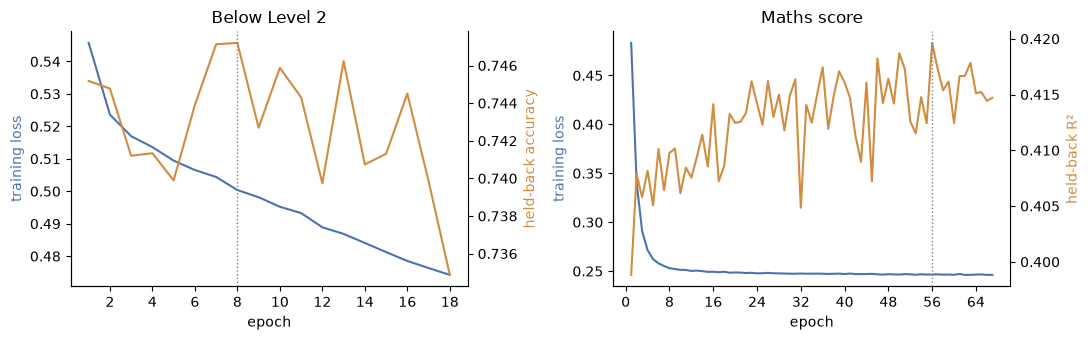

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, task, title, label in zip(axes, ["classification", "regression"], ["Below Level 2", "Maths score"],
                                  ["held-back accuracy", "held-back R²"]):
    net = nets[task]
    epochs = np.arange(1, net.n_iter_ + 1)
    ax.plot(epochs, net.loss_curve_, color="#4C72B0")
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_ylabel("training loss", color="#4C72B0")
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(epochs, net.validation_scores_, color="#D08C3F")
    ax2.axvline(np.argmax(net.validation_scores_) + 1, color="grey", ls=":", lw=1)
    ax2.spines["right"].set_visible(True)
    ax2.set_ylabel(label, color="#D08C3F")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_mlp_learning_curve.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** the classifier ran 18 epochs and kept the weights from epoch 8, the regressor ran 67 and kept epoch 56 (the dotted lines). Both stopped by themselves, well before the default limit of 200 epochs. The right-hand axes are zoomed in: the held-back accuracy only moves by about 0.01. The classifier's best held-back accuracy (0.7472) came in the first half, and after it the training loss kept falling while the held-back accuracy did not improve, so more epochs would only fit the training rows more closely. The regressor's training loss is flat after about 10 epochs, and its held-back R² was already 0.4164 in the first half against 0.4196 at its best. So in both the held-back score had flattened before training stopped.

# 3) Classification: below Level 2, all 10 PVs

In [7]:
clf_res = run("classification", best["classification"], PVS)
rubin(clf_res).round(3)

,score,se
roc_auc,0.812,0.004
pr_auc,0.900,0.002
balanced_acc,0.730,0.004
recall_below,0.817,0.012
recall_above,0.642,0.016


> **Note:** over all 10 PVs the ROC-AUC is 0.812 (se 0.004) and the PR-AUC 0.900. At the 0.5 threshold the balanced accuracy is 0.730 (se 0.004), with 81.7% of the students below Level 2 caught (se 1.2%) and 64.2% of those above it correctly left out (se 1.6%).

# 4) Regression: maths score, all 10 PVs

In [8]:
reg_res = run("regression", best["regression"], PVS)
rubin(reg_res).round(3)

,score,se
rmse,61.653,0.278
mae,48.364,0.253
r2,0.411,0.011


> **Note:** the RMSE is 61.65 points (se 0.28), the MAE 48.36 and R² 0.411 (se 0.011).

# 5) Results table
Both tasks in one long table, the same shape as `ahmed_hgb_results.csv`, so the two can be stacked.

In [9]:
results = pd.concat([rubin(clf_res).assign(task="classification"),
                     rubin(reg_res).assign(task="regression")])
results = results.rename_axis("metric").reset_index().assign(model="mlp")
results = results[["model", "task", "metric", "score", "se"]]
results.to_csv(OUT / "ahmed_mlp_results.csv", index=False)
results.round(3)

,model,task,metric,score,se
0,mlp,classification,roc_auc,0.812,0.004
1,mlp,classification,pr_auc,0.900,0.002
2,mlp,classification,balanced_acc,0.730,0.004
3,mlp,classification,recall_below,0.817,0.012
4,mlp,classification,recall_above,0.642,0.016
5,mlp,regression,rmse,61.653,0.278
6,mlp,regression,mae,48.364,0.253
7,mlp,regression,r2,0.411,0.011


> **Note:** among the 0 to 1 metrics the largest se is 0.016 (recall above Level 2), and the RMSE one is 0.28 points. The se already includes the spread across the 10 PVs.

# 6) MLP vs gradient boosting
We read the gradient boosting results from `03_baselines` and put the two side by side. Both used the same folds, the same weights and all 10 PVs, so the numbers are directly comparable. `diff` is MLP minus gradient boosting: for RMSE and MAE lower is better, so a positive `diff` there means the MLP is worse. `se_diff` combines the two standard errors as if they were independent. They share folds and PVs, so this is on the cautious side.

In [10]:
hgb = pd.read_csv(Path("../03_baselines/outputs") / "ahmed_hgb_results.csv")
both = hgb.merge(results, on=["task", "metric"], suffixes=("_hgb", "_mlp"))
both["diff"] = both["score_mlp"] - both["score_hgb"]
both["se_diff"] = np.sqrt(both["se_hgb"] ** 2 + both["se_mlp"] ** 2)
both = both[["task", "metric", "score_hgb", "se_hgb", "score_mlp", "se_mlp", "diff", "se_diff"]]
both.round(3)

,task,metric,score_hgb,se_hgb,score_mlp,se_mlp,diff,se_diff
0,classification,roc_auc,0.819,0.004,0.812,0.004,-0.006,0.006
1,classification,pr_auc,0.903,0.002,0.900,0.002,-0.004,0.003
2,classification,balanced_acc,0.735,0.004,0.730,0.004,-0.005,0.006
3,classification,recall_below,0.823,0.004,0.817,0.012,-0.006,0.013
4,classification,recall_above,0.647,0.009,0.642,0.016,-0.005,0.018
5,regression,rmse,60.750,0.328,61.653,0.278,0.903,0.430
6,regression,mae,47.675,0.276,48.364,0.253,0.689,0.375
7,regression,r2,0.428,0.012,0.411,0.011,-0.017,0.016


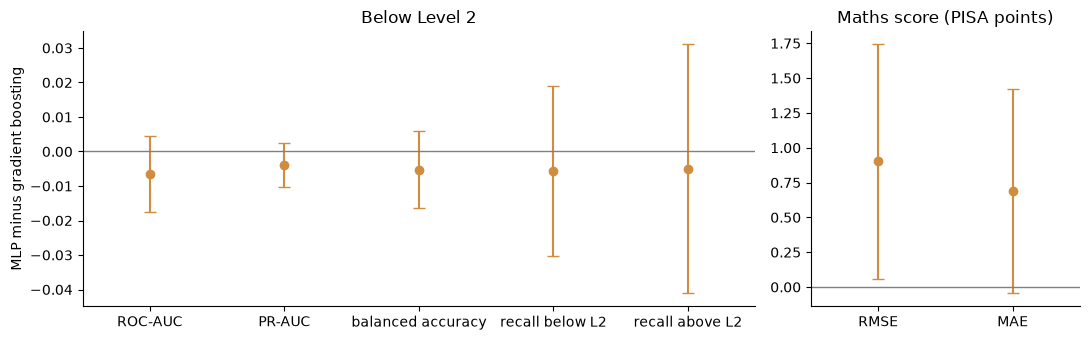

In [11]:
NAMES = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "balanced_acc": "balanced accuracy",
         "recall_below": "recall below L2", "recall_above": "recall above L2", "rmse": "RMSE", "mae": "MAE"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [5, 2]})
for ax, task, title in zip(axes, ["classification", "regression"], ["Below Level 2", "Maths score (PISA points)"]):
    d = both[(both["task"] == task) & (both["metric"] != "r2")]
    x = np.arange(len(d))
    ax.errorbar(x, d["diff"], yerr=1.96 * d["se_diff"], fmt="o", color="#D08C3F", capsize=4)
    ax.axhline(0, color="grey", lw=1)
    ax.set_xticks(x, d["metric"].map(NAMES))
    ax.set_xlim(-0.5, len(d) - 0.5)
    ax.set_title(title)
axes[0].set_ylabel("MLP minus gradient boosting")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_mlp_vs_hgb.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** each point is MLP minus gradient boosting for one metric, with a 95% interval (1.96 se_diff). For the 0 to 1 metrics below zero means the MLP scored lower, and for RMSE and MAE above zero means the MLP is worse. R² is left out of the plot because it isn't in PISA points, but it's in the table. The MLP is behind on the headline metrics. On the regression errors the gap is RMSE 0.90 points worse with se_diff 0.43, and MAE 0.69 with se_diff 0.37, about 2.1 and 1.8 se. For ROC-AUC the gap is -0.006 with se_diff 0.006, about 1.1 se. Only gaps above about 2 se count as clear. So the MLP is probably a little worse on the maths score (about 2 se), and the ROC-AUC gap is within the noise. R² is behind too (-0.017, se_diff 0.016, about 1.1 se). Its se is bigger next to its gap because R² also changes with how spread out the scores are in each PV and test fold, so for the maths score we go by the RMSE.

# 7) Summary

- MLP on the 17 predictors and their `_missing` flags (median fill and scaling inside the pipeline), tuned on PV1 with a 12-setting grid, then run on all 10 PVs and 5 school folds. It picked two hidden layers of 128 and 64 for both tasks, with `alpha` 0.01 for classification and 1.0 for regression (`outputs/ahmed_mlp_params.json`). The regression penalty is at the top of the grid, but the gain from it was small (0.08 points of RMSE on PV1). Early stopping ended both networks after the held-back score had flattened (18 and 67 epochs).
- Pooled, below Level 2: ROC-AUC 0.812 (se 0.004), balanced accuracy 0.730 (se 0.004), recall 0.817 below and 0.642 above Level 2. Maths score: RMSE 61.65 points (se 0.28), R² 0.411 (se 0.011). All in `outputs/ahmed_mlp_results.csv`.
- Against gradient boosting the MLP is behind on the headline metrics: ROC-AUC by 0.006 (about 1.1 se), RMSE by 0.90 points (about 2.1 se) and R² by 0.017 (about 1.1 se). Only the RMSE gap is about 2 se, so it is probably real. The other two are within the noise. R² points the same way as the RMSE. Its se is bigger next to its gap because R² also changes with how spread out the scores are in each PV and test fold, so we read the maths-score result from the RMSE: the MLP is probably a little worse. So gradient boosting stays our main model: it's as good or better, and it needs no filling or scaling.

Next: both result tables go into the R4 section of the report, next to the ablations in `../03_baselines/ahmed_ablations.ipynb`.